> **Daffa was here**

In [1]:
from pathlib import Path
import json
import os
import random

import numpy as np
import pandas as pd
import torch

RANDOM_SEED = int(os.environ.get('SKIN_RANDOM_SEED', '42'))
CLASS_NAMES = ('AK', 'BCC', 'MEL', 'NV', 'SCC')
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def findProjectRoot(startPath: Path) -> Path:
    for candidateRoot in (startPath, *startPath.parents):
        if (candidateRoot / 'data' / 'processed').exists() and (candidateRoot / 'notebooks').exists():
            return candidateRoot
    raise RuntimeError('Run from the skin-domain-shift project or one of its subdirectories.')

projectRoot = findProjectRoot(Path.cwd().resolve())
processedRoot = projectRoot / 'data' / 'processed'
artifactRoot = projectRoot / 'artifacts' / 'ds'
figureRoot = projectRoot / 'reports' / 'figures' / 'ds'
reportRoot = projectRoot / 'reports'
artifactRoot.mkdir(parents=True, exist_ok=True)
figureRoot.mkdir(parents=True, exist_ok=True)

def fromProjectPath(pathValue: str) -> Path:
    return (projectRoot / Path(pathValue)).resolve()

runMode = os.environ.get('SKIN_RUN_MODE', 'full').strip().lower()
if runMode not in {'smoke', 'full'}:
    raise ValueError('SKIN_RUN_MODE must be smoke or full.')
runModeRoot = artifactRoot / runMode
runFigureModeRoot = figureRoot / runMode
runArtifactRoot = runModeRoot / f'seed{RANDOM_SEED}'
runFigureRoot = runFigureModeRoot / f'seed{RANDOM_SEED}'
runArtifactRoot.mkdir(parents=True, exist_ok=True)
runFigureRoot.mkdir(parents=True, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Project root: {projectRoot}')
print(f'Run mode: {runMode}; seed: {RANDOM_SEED}')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU Avail')

Project root: D:\sunib\Research\Skin\skin-domain-shift
Run mode: full; seed: 42
Device: cuda
GPU Avail


In [2]:
from contextlib import nullcontext
import hashlib
import time

from PIL import Image
from sklearn.metrics import balanced_accuracy_score, f1_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from tqdm.auto import tqdm

experimentConfigPath = runArtifactRoot / 'experimentConfig.json'
if not experimentConfigPath.exists():
    raise FileNotFoundError('Run 00_experimentSetup.ipynb first.')
experimentConfig = json.loads(experimentConfigPath.read_text(encoding='utf-8'))
if experimentConfig['randomSeed'] != RANDOM_SEED:
    raise ValueError('Experiment config seed does not match SKIN_RANDOM_SEED.')
if tuple(experimentConfig['classNames']) != CLASS_NAMES:
    raise ValueError('Experiment class order does not match this notebook.')

trainManifestPath = processedRoot / 'clinicalTrain.csv'
valManifestPath = processedRoot / 'clinicalVal.csv'
trainFrame = pd.read_csv(trainManifestPath, low_memory=False)
valFrame = pd.read_csv(valManifestPath, low_memory=False)

imageSize = int(os.environ.get('SKIN_IMAGE_SIZE', '224'))
batchSize = int(os.environ.get('SKIN_BATCH_SIZE', '32' if runMode == 'full' else '8'))
warmupEpochs = int(os.environ.get('SKIN_WARMUP_EPOCHS', '3' if runMode == 'full' else '1'))
fineTuneEpochs = int(os.environ.get('SKIN_FINETUNE_EPOCHS', '12' if runMode == 'full' else '0'))
earlyStoppingPatience = int(os.environ.get('SKIN_PATIENCE', '4'))
workerCount = int(os.environ.get('SKIN_WORKERS', '0'))
useAmp = device.type == 'cuda'

if runMode == 'smoke':
    trainFrame = trainFrame.groupby('harmonizedLabel', group_keys=False).head(4).reset_index(drop=True)
    valFrame = valFrame.groupby('harmonizedLabel', group_keys=False).head(2).reset_index(drop=True)

print({
    'trainRows': len(trainFrame), 'valRows': len(valFrame), 'batchSize': batchSize,
    'warmupEpochs': warmupEpochs, 'fineTuneEpochs': fineTuneEpochs, 'useAmp': useAmp,
})

{'trainRows': 1479, 'valRows': 290, 'batchSize': 32, 'warmupEpochs': 3, 'fineTuneEpochs': 12, 'useAmp': True}


In [3]:
class SkinImageDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, transform, classNames: tuple[str, ...]):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform
        self.classToIndex = {className: index for index, className in enumerate(classNames)}

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int, str]:
        row = self.frame.iloc[index]
        imagePath = fromProjectPath(row['imagePath'])
        with Image.open(imagePath) as image:
            rgbImage = image.convert('RGB')
        imageTensor = self.transform(rgbImage)
        labelIndex = self.classToIndex[row['harmonizedLabel']]
        return imageTensor, labelIndex, row['imageId']

imageNetMean = [0.485, 0.456, 0.406]
imageNetStd = [0.229, 0.224, 0.225]
trainTransform = transforms.Compose([
    transforms.RandomResizedCrop(imageSize, scale=(0.80, 1.0), ratio=(0.85, 1.15)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(imageNetMean, imageNetStd),
])
evaluationTransform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(imageSize),
    transforms.ToTensor(),
    transforms.Normalize(imageNetMean, imageNetStd),
])

trainDataset = SkinImageDataset(trainFrame, trainTransform, CLASS_NAMES)
valDataset = SkinImageDataset(valFrame, evaluationTransform, CLASS_NAMES)
dataGenerator = torch.Generator().manual_seed(RANDOM_SEED)
trainLoader = DataLoader(
    trainDataset, batch_size=batchSize, shuffle=True, num_workers=workerCount,
    pin_memory=useAmp, generator=dataGenerator,
)
valLoader = DataLoader(
    valDataset, batch_size=batchSize, shuffle=False, num_workers=workerCount, pin_memory=useAmp,
)

sampleImages, sampleLabels, sampleIds = next(iter(trainLoader))
assert sampleImages.ndim == 4 and sampleImages.shape[1:] == (3, imageSize, imageSize)
assert sampleLabels.min() >= 0 and sampleLabels.max() < len(CLASS_NAMES)
print(f'Synthetic contract check via real batch passed: {tuple(sampleImages.shape)}')

Synthetic contract check via real batch passed: (32, 3, 224, 224)


In [4]:
modelWeights = models.MobileNet_V3_Small_Weights.DEFAULT
model = models.mobilenet_v3_small(weights=modelWeights)
model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(CLASS_NAMES))
model = model.to(device)

fullTrainFrame = pd.read_csv(trainManifestPath, low_memory=False)
trainCounts = fullTrainFrame['harmonizedLabel'].value_counts().reindex(CLASS_NAMES)
classWeightValues = len(fullTrainFrame) / (len(CLASS_NAMES) * trainCounts)
classWeightTensor = torch.tensor(classWeightValues.values, dtype=torch.float32, device=device)
lossFunction = nn.CrossEntropyLoss(weight=classWeightTensor)
gradientScaler = torch.amp.GradScaler('cuda', enabled=useAmp)

def setFeatureTraining(model: nn.Module, trainFeatures: bool) -> None:
    for parameter in model.features.parameters():
        parameter.requires_grad = trainFeatures
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True

def trainOneEpoch(model: nn.Module, dataLoader: DataLoader, optimizer: torch.optim.Optimizer) -> float:
    model.train()
    totalLoss = 0.0
    for images, labels, _ in tqdm(dataLoader, leave=False, desc='Training'):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        ampContext = torch.amp.autocast('cuda', enabled=useAmp) if useAmp else nullcontext()
        with ampContext:
            logits = model(images)
            loss = lossFunction(logits, labels)
        gradientScaler.scale(loss).backward()
        gradientScaler.step(optimizer)
        gradientScaler.update()
        totalLoss += float(loss.detach()) * len(labels)
    return totalLoss / len(dataLoader.dataset)

@torch.inference_mode()
def evaluateModel(model: nn.Module, dataLoader: DataLoader) -> dict:
    model.eval()
    trueLabels = []
    predictedLabels = []
    totalLoss = 0.0
    for images, labels, _ in tqdm(dataLoader, leave=False, desc='Validating'):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        ampContext = torch.amp.autocast('cuda', enabled=useAmp) if useAmp else nullcontext()
        with ampContext:
            logits = model(images)
            loss = lossFunction(logits, labels)
        totalLoss += float(loss.detach()) * len(labels)
        trueLabels.extend(labels.cpu().tolist())
        predictedLabels.extend(logits.argmax(dim=1).cpu().tolist())
    return {
        'loss': totalLoss / len(dataLoader.dataset),
        'macroF1': f1_score(trueLabels, predictedLabels, average='macro', zero_division=0),
        'balancedAccuracy': balanced_accuracy_score(trueLabels, predictedLabels),
    }

def manifestSha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()

In [5]:
checkpointPath = runArtifactRoot / 'bestModel.pt'
historyPath = runArtifactRoot / 'trainingHistory.csv'
trainingMetadataPath = runArtifactRoot / 'trainingMetadata.json'

historyRows = []
bestValMacroF1 = -1.0
epochsWithoutImprovement = 0
startTime = time.perf_counter()

trainingPhases = [
    {'phaseName': 'classifierWarmup', 'epochs': warmupEpochs, 'trainFeatures': False, 'learningRate': 1e-3},
    {'phaseName': 'fullFineTune', 'epochs': fineTuneEpochs, 'trainFeatures': True, 'learningRate': 1e-4},
]
epochNumber = 0
stopTraining = False
for phase in trainingPhases:
    if phase['epochs'] <= 0 or stopTraining:
        continue
    setFeatureTraining(model, phase['trainFeatures'])
    optimizer = torch.optim.AdamW(
        (parameter for parameter in model.parameters() if parameter.requires_grad),
        lr=phase['learningRate'], weight_decay=1e-4,
    )
    for _ in range(phase['epochs']):
        epochNumber += 1
        trainLoss = trainOneEpoch(model, trainLoader, optimizer)
        valMetrics = evaluateModel(model, valLoader)
        historyRow = {
            'epoch': epochNumber,
            'phase': phase['phaseName'],
            'trainLoss': trainLoss,
            'valLoss': valMetrics['loss'],
            'valMacroF1': valMetrics['macroF1'],
            'valBalancedAccuracy': valMetrics['balancedAccuracy'],
        }
        historyRows.append(historyRow)
        print({key: round(value, 5) if isinstance(value, float) else value for key, value in historyRow.items()})

        if valMetrics['macroF1'] > bestValMacroF1 + 1e-6:
            bestValMacroF1 = valMetrics['macroF1']
            epochsWithoutImprovement = 0
            torch.save({
                'modelName': 'mobilenet_v3_small',
                'stateDict': model.state_dict(),
                'classNames': list(CLASS_NAMES),
                'imageSize': imageSize,
                'randomSeed': RANDOM_SEED,
                'runMode': runMode,
                'bestEpoch': epochNumber,
                'bestValMacroF1': float(bestValMacroF1),
                'trainManifestSha256': manifestSha256(trainManifestPath),
                'valManifestSha256': manifestSha256(valManifestPath),
            }, checkpointPath)
        else:
            epochsWithoutImprovement += 1
        if epochsWithoutImprovement >= earlyStoppingPatience:
            stopTraining = True
            print(f'Early stopping after epoch {epochNumber}.')
            break

elapsedSeconds = time.perf_counter() - startTime
historyFrame = pd.DataFrame(historyRows)
historyFrame.to_csv(historyPath, index=False)
if not checkpointPath.exists():
    raise RuntimeError('Training did not produce a checkpoint.')
trainingMetadata = {
    'runMode': runMode,
    'randomSeed': RANDOM_SEED,
    'device': str(device),
    'gpuName': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'elapsedSeconds': elapsedSeconds,
    'epochCount': len(historyRows),
    'bestValMacroF1': float(bestValMacroF1),
    'checkpointPath': str(checkpointPath.relative_to(projectRoot).as_posix()),
    'paperResultsEligible': runMode == 'full',
}
trainingMetadataPath.write_text(json.dumps(trainingMetadata, indent=2), encoding='utf-8')
print(json.dumps(trainingMetadata, indent=2))
if runMode == 'smoke':
    print('SMOKE ONLY: these metrics are not valid paper results.')

Training:   0%|          | 0/47 [00:00<?, ?it/s]

Validating:   0%|          | 0/10 [00:00<?, ?it/s]

{'epoch': 1, 'phase': 'classifierWarmup', 'trainLoss': 1.2774, 'valLoss': 1.22348, 'valMacroF1': 0.49748, 'valBalancedAccuracy': np.float64(0.49111)}


Training:   0%|          | 0/47 [00:00<?, ?it/s]

Validating:   0%|          | 0/10 [00:00<?, ?it/s]

...

Validating:   0%|          | 0/10 [00:00<?, ?it/s]

{'epoch': 9, 'phase': 'fullFineTune', 'trainLoss': 0.48408, 'valLoss': 1.17923, 'valMacroF1': 0.54595, 'valBalancedAccuracy': np.float64(0.54482)}


Training:   0%|          | 0/47 [00:00<?, ?it/s]

Validating:   0%|          | 0/10 [00:00<?, ?it/s]

{'epoch': 10, 'phase': 'fullFineTune', 'trainLoss': 0.48305, 'valLoss': 1.15254, 'valMacroF1': 0.55452, 'valBalancedAccuracy': np.float64(0.55382)}
Early stopping after epoch 10.
{
  "runMode": "full",
  "randomSeed": 2026,
  "device": "cuda",
  "gpuName": "NVIDIA GeForce RTX 3070 Laptop GPU",
  "elapsedSeconds": 1236.1487680999562,
  "epochCount": 10,
  "bestValMacroF1": 0.5694444255434968,
  "checkpointPath": "artifacts/ds/full/seed2026/bestModel.pt",
  "paperResultsEligible": true
}


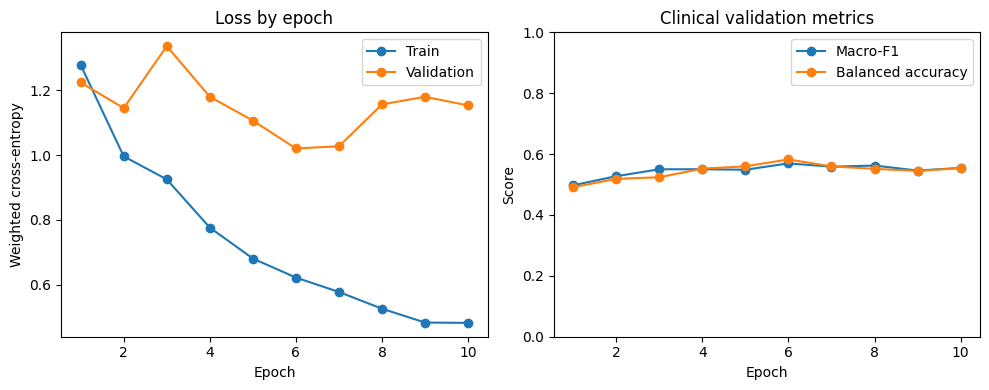

In [6]:
import matplotlib.pyplot as plt

historyFigurePath = runFigureRoot / 'trainingHistory.png'
figure, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(historyFrame['epoch'], historyFrame['trainLoss'], marker='o', label='Train')
axes[0].plot(historyFrame['epoch'], historyFrame['valLoss'], marker='o', label='Validation')
axes[0].set(title='Loss by epoch', xlabel='Epoch', ylabel='Weighted cross-entropy')
axes[0].legend()
axes[1].plot(historyFrame['epoch'], historyFrame['valMacroF1'], marker='o', label='Macro-F1')
axes[1].plot(historyFrame['epoch'], historyFrame['valBalancedAccuracy'], marker='o', label='Balanced accuracy')
axes[1].set(title='Clinical validation metrics', xlabel='Epoch', ylabel='Score', ylim=(0, 1))
axes[1].legend()
figure.tight_layout()
figure.savefig(historyFigurePath, dpi=300, bbox_inches='tight')
plt.show()